<a href="https://colab.research.google.com/github/Jashan-Khangura/learn-pytorch/blob/main/pytorch_image_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐾 Welcome to Animal Face Classifier!

In this notebook, we are going to build an AI that can look at pictures of animals and guess if they are a **Cat**, a **Dog**, or a **Wild animal**.

Think of this like teaching a newborn puppy how to recognize its friends!

In [ ]:
!pip install opendatasets legacy-cgi --quiet
import opendatasets as od
od.download("https://www.kaggle.com/datasets/andrewmvd/animal-faces")

## Step 1: Loading our Toy Box (Downloading Data)

### 📦 What are we doing here?
We are bringing a massive digital box of animal pictures (dataset) from a website called Kaggle into our computer.

### 💡 Why do we do this?
An AI cannot learn without examples! Just like a child needs a picture book of animals to learn what a "cat" looks like, our AI needs thousands of pictures to study.

In [ ]:
import torch # Main PyTorch Library
from torch import nn # Used for creating the layers and loss function
from torch.optim import Adam # Adam Optimizer
import torchvision.transforms as transforms # Transform function used to modify and preprocess all the images
from torch.utils.data import Dataset, DataLoader # Dataset class and DataLoader for creating the objects
from sklearn.preprocessing import LabelEncoder # Label Encoder to encode the classes from strings to numbers
import matplotlib.pyplot as plt # Used for visualizing the images and plotting the training progress
from PIL import Image # Used to read the images from the directory
import pandas as pd # Used to read/create dataframes (csv) and process tabular data
import numpy as np # preprocessing and numerical/mathematical operations
import os # Used to read the images path from the directory

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device available:", device)

Device available: cuda


## Step 2: Getting our Tools Ready (Imports & Hardware)

### 🛠️ What are we doing here?
We are bringing in special toolboxes (libraries):
* **PyTorch (`torch`)**: The magical engine that builds and trains our AI.
* **Matplotlib (`plt`)**: Our drawing kit to plot graphs later.
* **PIL (`Image`)**: Our virtual eyes to open and read image files.
* **Device Selection**: Checking if we have a super-fast brain helper called a **GPU** (`cuda`) or if we must use the standard brain (`cpu`).

In [ ]:
image_paths = []
labels = []

for i in os.listdir("/content/animal-faces/afhq/"):
  for label in os.listdir(f"/content/animal-faces/afhq/{i}"):
    for image in os.listdir(f"/content/animal-faces/afhq/{i}/{label}"):
      image_paths.append(f"/content/animal-faces/afhq/{i}/{label}/{image}")
      labels.append(label)

data_df = pd.DataFrame(zip(image_paths, labels), columns=['image_path', 'label'])
data_df.head()

,image_path,label
0,/content/animal-faces/afhq/train/wild/flickr_w...,wild
1,/content/animal-faces/afhq/train/wild/pixabay_...,wild
2,/content/animal-faces/afhq/train/wild/flickr_w...,wild
3,/content/animal-faces/afhq/train/wild/flickr_w...,wild
4,/content/animal-faces/afhq/train/wild/flickr_w...,wild


## Step 3: Making an Inventory List

### 📝 What are we doing here?
We are walking through all the folders we downloaded, writing down the exact location of every single photo (`image_paths`), and noting down whether it is a cat, dog, or wild animal (`labels`). We put this into a neat spreadsheet table (`DataFrame`).

### 💡 Real-world Example:
Imagine having a giant box of physical photos. Before showing them to a child, you create an index card list:
* Card 1: `"/box/photo_42.jpg" -> Dog`
* Card 2: `"/box/photo_99.jpg" -> Cat`

In [ ]:
train = data_df.sample(frac=0.7, random_state=7)
test = data_df.drop(train.index)

val = test.sample(frac=0.5, random_state=7)
test = test.drop(val.index)

label_encoder = LabelEncoder()
label_encoder.fit(data_df['label'])

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.ConvertImageDtype(torch.float)
  ])

## Step 4: Splitting the Books & Standardizing the Photos

### ✂️ Splitting the Data:
We split our photos into 3 distinct piles:
1. **Train Pile (70%)**: The textbook the AI studies from.
2. **Validation Pile (15%)**: A mini-quiz we give the AI *during* studying to see if it's getting smarter.
3. **Test Pile (15%)**: The final exam at the very end with questions it has never seen before!

### 📏 Image Transformations (`transforms`):
AI is very picky. It needs all images to be the exact same size. Here, we resize every photo to `128x128` pixels and convert them to numbers (tensors) that PyTorch can calculate.

In [ ]:
class CustomImageDataset(Dataset):
  def __init__(self, dataframe, transform=None):
    self.dataframe = dataframe
    self.transform = transform
    self.labels = torch.tensor(label_encoder.transform(dataframe['label'])).to(device)

  def __len__(self):
    return self.dataframe.shape[0]

  def __getitem__(self, idx):
    img_path = self.dataframe.iloc[idx, 0]
    label = self.labels[idx]
    image = Image.open(img_path).convert('RGB')
    if self.transform:
      image = self.transform(image).to(device)

    return image, label

## Step 5: Designing the "Conveyor Belt" (Custom Dataset)

### 🏭 What is this Class doing?
We built a custom assistant (`CustomImageDataset`) that knows how to:
1. Find the photo on the computer.
2. Open it up.
3. Apply our resize/conversion rules.
4. Deliver the photo along with its correct label.

In [ ]:
train_dataset = CustomImageDataset(dataframe=train, transform=transform)
val_dataset = CustomImageDataset(dataframe=val, transform=transform)
test_dataset = CustomImageDataset(dataframe=test, transform=transform)

LR = 1e-4
BATCH_SIZE = 16
EPOCHS = 10

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=True)

## Step 6: Packing them in Lunchboxes (DataLoaders)

### 🍱 What are DataLoaders?
Instead of feeding the AI all 16,000 pictures at once (which would make its brain explode), or one-by-one (which takes forever), we group them into "lunchboxes" of **16 pictures** at a time (`BATCH_SIZE = 16`).

We also shuffle the training photos so the AI doesn't just memorize the order of the pictures!

In [ ]:
class Net(nn.Module):
  def __init__(self):
    super().__init__()

    self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
    self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
    self.pooling = nn.MaxPool2d(2,2)
    self.relu = nn.ReLU()

    self.flatten = nn.Flatten()
    self.linear = nn.Linear((128*16*16), 128)
    self.output = nn.Linear(128, len(data_df['label'].unique()))

  def forward(self, x):
    x = self.conv1(x) # -> Outputs: (32, 128, 128)
    x = self.pooling(x)# -> Outputs: (32, 64, 64)
    x = self.relu(x)
    x = self.conv2(x) # -> Outputs: (64, 64, 64)
    x = self.pooling(x) # -> Outputs: (64, 32, 32)
    x = self.relu(x)
    x = self.conv3(x) # -> Outputs: (128, 32, 32)
    x = self.pooling(x) # -> Outputs: (128, 16, 16)
    x = self.relu(x)
    x = self.flatten(x)
    x = self.linear(x)
    x = self.output(x)

    return x

model = Net().to(device)

## Step 7: Building the Artificial Brain (Neural Network)

This is the most exciting part! We are building a **Convolutional Neural Network (CNN)**.

### 🧠 How does this "Brain" work?
Imagine looking at a picture of a cat. Your brain looks for features:
1. **First Layers (`conv1`)**: Detects simple things like sharp lines, borders, and edges.
2. **Middle Layers (`conv2`, `conv3`)**: Combines edges to find shapes (like round eyes, pointy ears).
3. **Pooling (`MaxPool2d`)**: Shrinks the picture size to focus only on the most important details (like squinting your eyes to see the main shape).
4. **Linear Layers**: Looks at all these gathered clues and votes: "Is this a Cat, Dog, or Wild Animal?"

In [ ]:
from torchsummary import summary
summary(model, input_size = (3, 128, 128))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
         MaxPool2d-2           [-1, 32, 64, 64]               0
              ReLU-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 64, 64, 64]          18,496
         MaxPool2d-5           [-1, 64, 32, 32]               0
              ReLU-6           [-1, 64, 32, 32]               0
            Conv2d-7          [-1, 128, 32, 32]          73,856
         MaxPool2d-8          [-1, 128, 16, 16]               0
              ReLU-9          [-1, 128, 16, 16]               0
          Flatten-10                [-1, 32768]               0
           Linear-11                  [-1, 128]       4,194,432
           Linear-12                    [-1, 3]             387
Total params: 4,288,067
Trainable params: 4,288,067
Non-trainable params: 0
---------------------------

## Step 8: Brain Map Summary

### 📋 What is this?
This prints out a map of our brain! It shows us how the image changes size as it goes deeper through the layers, and how many virtual "brain cells" (parameters) it has. We have about **4.2 Million** connections to train!

In [ ]:
criterion = nn.CrossEntropyLoss() # Cross Entropy Loss
optimizer = Adam(model.parameters(), lr=LR) # Adam optimizer

## Step 9: The Teacher & The Grader

### 📝 The Grader (`CrossEntropyLoss`):
This is the grading system. When the AI guesses "Dog" but the picture was a "Cat", this formula calculates exactly *how wrong* the AI was.

### 📈 The Teacher (`Adam Optimizer`):
This is the coach. Once we know how wrong the AI was, the Optimizer goes back and adjusts the 4.2 million brain connections slightly so it does better next time. The Learning Rate (`LR = 1e-4`) controls how tiny those adjustments are.

In [ ]:
total_loss_train_plot = []
total_loss_validation_plot = []
total_acc_train_plot = []
total_acc_validation_plot = []


for epoch in range(EPOCHS):
  total_acc_train = 0
  total_loss_train = 0
  total_loss_val = 0
  total_acc_val = 0

  for inputs, labels in train_loader:
    optimizer.zero_grad()
    outputs = model(inputs)
    train_loss = criterion(outputs, labels)
    total_loss_train += train_loss.item()
    train_loss.backward()

    train_acc = (torch.argmax(outputs, axis=1) == labels).sum().item()
    total_acc_train += train_acc

    optimizer.step()

  with torch.no_grad():
    for inputs, labels in val_loader:
      outputs = model(inputs)
      val_loss = criterion(outputs, labels)
      total_loss_val += val_loss.item()

      val_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
      total_acc_val += val_acc

  total_loss_train_plot.append(round(total_loss_train/1000, 4))
  total_loss_validation_plot.append(round(total_loss_val/1000, 4))
  total_acc_train_plot.append(round(total_acc_train/(train_dataset.__len__())*100, 4))
  total_acc_validation_plot.append(round(total_acc_val/(val_dataset.__len__())*100, 4))
  print(f'''Epoch {epoch+1}/{EPOCHS}, Train Loss: {round(total_loss_train/100, 4)} Train Accuracy {round((total_acc_train)/train_dataset.__len__() * 100, 4)}
              Validation Loss: {round(total_loss_val/100, 4)} Validation Accuracy: {round((total_acc_val)/val_dataset.__len__() * 100, 4)}''')
  print("="*25)

Epoch 1/10, Train Loss: 3.4009 Train Accuracy 79.8601
              Validation Loss: 0.3988 Validation Accuracy: 90.9504
Epoch 2/10, Train Loss: 1.5099 Train Accuracy 92.0556
              Validation Loss: 0.2572 Validation Accuracy: 94.3388
Epoch 3/10, Train Loss: 0.9424 Train Accuracy 95.2351
              Validation Loss: 0.1794 Validation Accuracy: 95.4132
Epoch 4/10, Train Loss: 0.6284 Train Accuracy 96.7851
              Validation Loss: 0.207 Validation Accuracy: 95.4545
Epoch 5/10, Train Loss: 0.4541 Train Accuracy 97.7504
              Validation Loss: 0.1511 Validation Accuracy: 96.4876
Epoch 6/10, Train Loss: 0.3462 Train Accuracy 98.3438
              Validation Loss: 0.1514 Validation Accuracy: 96.7355
Epoch 7/10, Train Loss: 0.2544 Train Accuracy 98.7512
              Validation Loss: 0.1445 Validation Accuracy: 96.8182
Epoch 8/10, Train Loss: 0.1993 Train Accuracy 99.1055
              Validation Loss: 0.1734 Validation Accuracy: 96.3636
Epoch 9/10, Train Loss: 0.1208 Tr

## Step 10: Training School (The Study Loops)

### 🏫 What is happening here?
We let the AI study all the images **10 times** (`EPOCHS = 10`).
For each epoch:
1. **Study**: The AI looks at a batch of 16 pictures, makes guesses, calculates how wrong it was, and the coach adjusts the brain connections.
2. **Quiz**: We turn off studying mode (`torch.no_grad()`) and quiz the AI on the Validation Pile to see how well it's doing on pictures it didn't use for adjusting its brain.

As you can see from the outputs, the validation accuracy starts at **90%** and climbs up to **96%**! 🌟

In [ ]:
with torch.no_grad():
  total_loss_test = 0
  total_acc_test = 0

  for inputs, labels in test_loader:
    predictions = model(inputs)

    test_loss = criterion(predictions, labels)
    total_loss_test += test_loss.item()

    test_acc = (torch.argmax(predictions, axis = 1) == labels).sum().item()
    total_acc_test += test_acc

print(f"Accuracy Score is: {round((total_acc_test/test_dataset.__len__()) * 100, 4)} and Loss is {round(total_loss_test/1000, 4)}")

Accuracy Score is: 96.2795 and Loss is 0.0185


## Step 11: The Final Exam!

### 🎓 What is this doing?
Now that the AI is done studying, we give it the **Final Exam** using the Test Pile. The AI has *never* seen these pictures before, and we don't adjust its brain anymore.

**Result:** Your AI scored a whopping **96.28%** on the final exam! That is an A+! 🥳

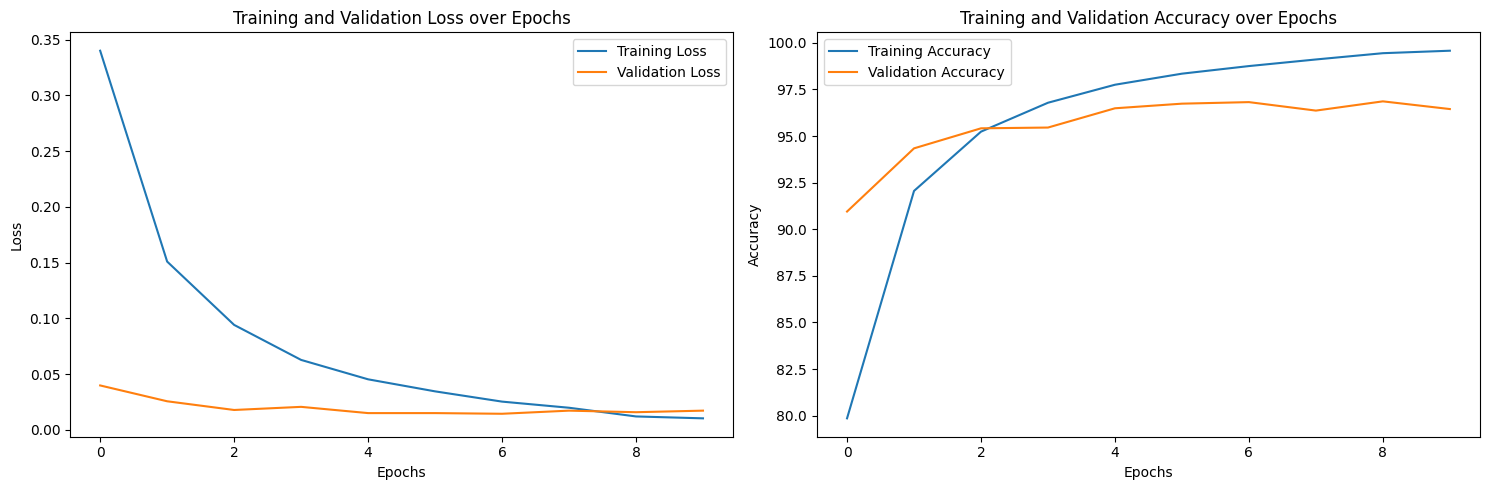

In [ ]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

axs[0].plot(total_loss_train_plot, label='Training Loss')
axs[0].plot(total_loss_validation_plot, label='Validation Loss')
axs[0].set_title('Training and Validation Loss over Epochs')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend()

axs[1].plot(total_acc_train_plot, label='Training Accuracy')
axs[1].plot(total_acc_validation_plot, label='Validation Accuracy')
axs[1].set_title('Training and Validation Accuracy over Epochs')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend()

plt.tight_layout()

plt.show()

## Step 12: Visualizing the Report Card

### 📊 What are we looking at?
We draw two graphs:
1. **Loss Graph (Left)**: Shows how the AI's mistakes (Loss) decreased over time. Downward is good!
2. **Accuracy Graph (Right)**: Shows how many answers the AI got right over time. Upward is good!

Because both training and validation lines move nicely together, it means our AI successfully learned the features of animal faces instead of just memorizing the pictures!